In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240612_CAT16_C10_W3_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240612_CAT16_C10_W3_run2.DSC", exp_type="francklab_esr/romana") # heating 1 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'cooling 1')

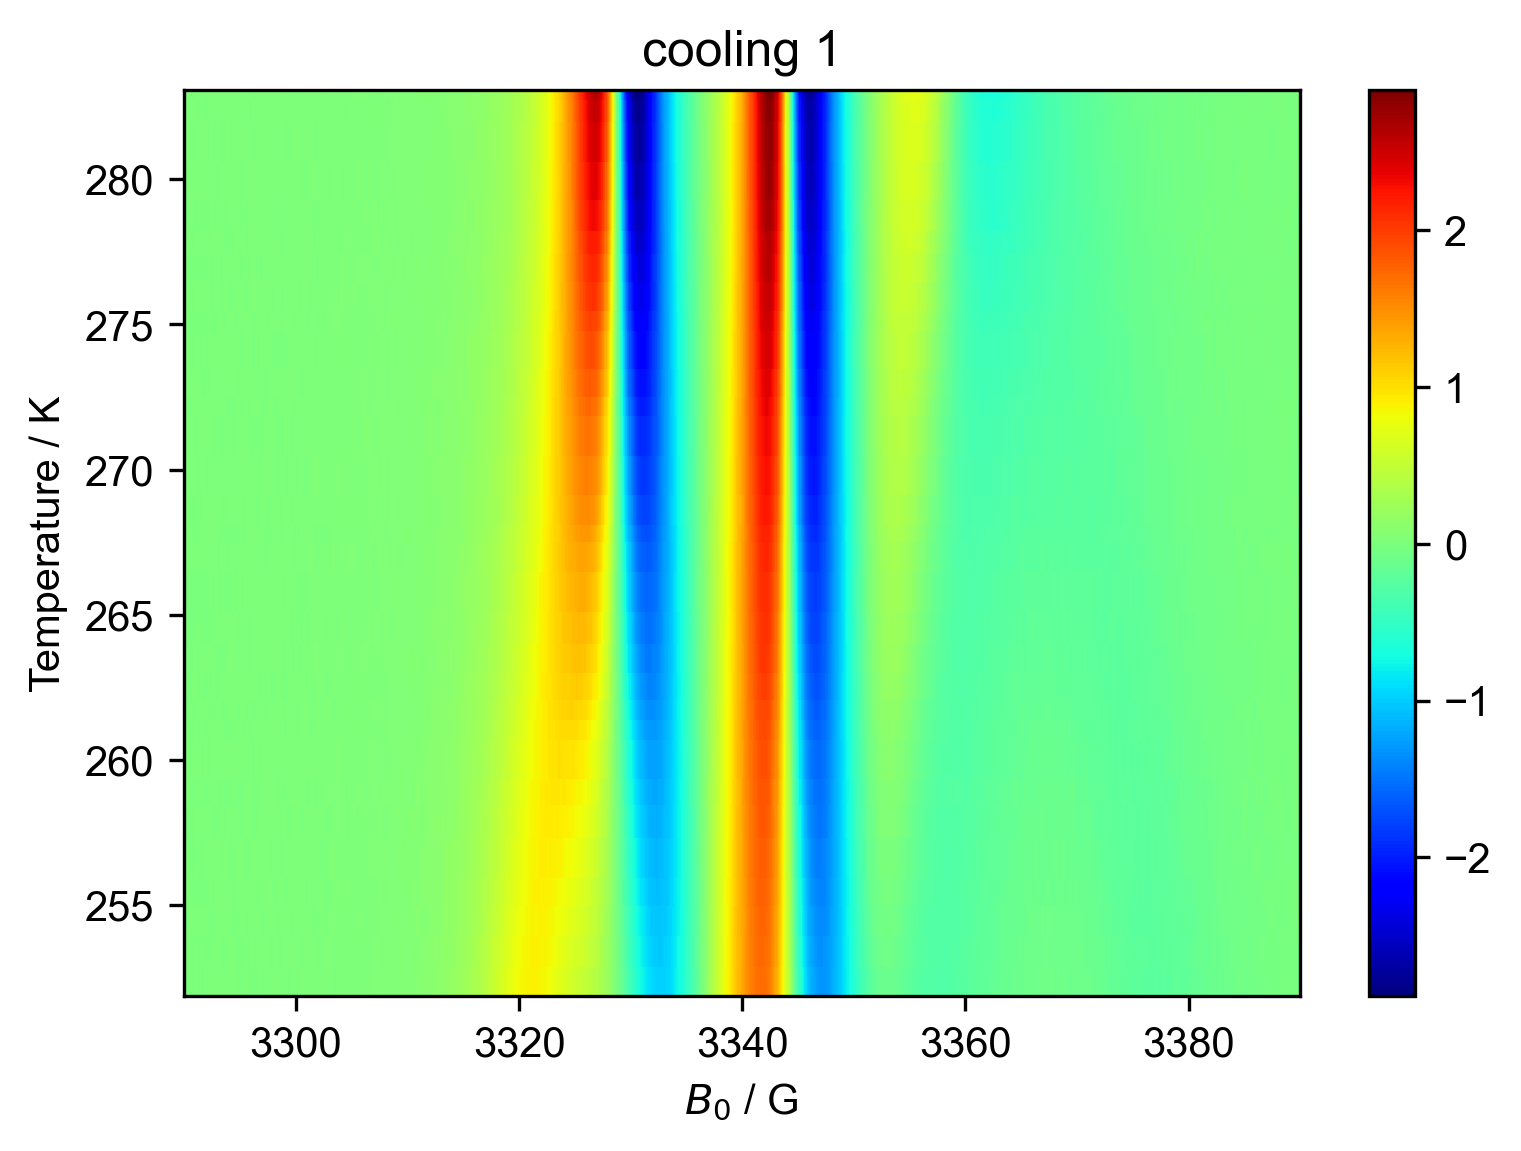

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("cooling 1")

Text(0.5, 1.0, 'heating 1')

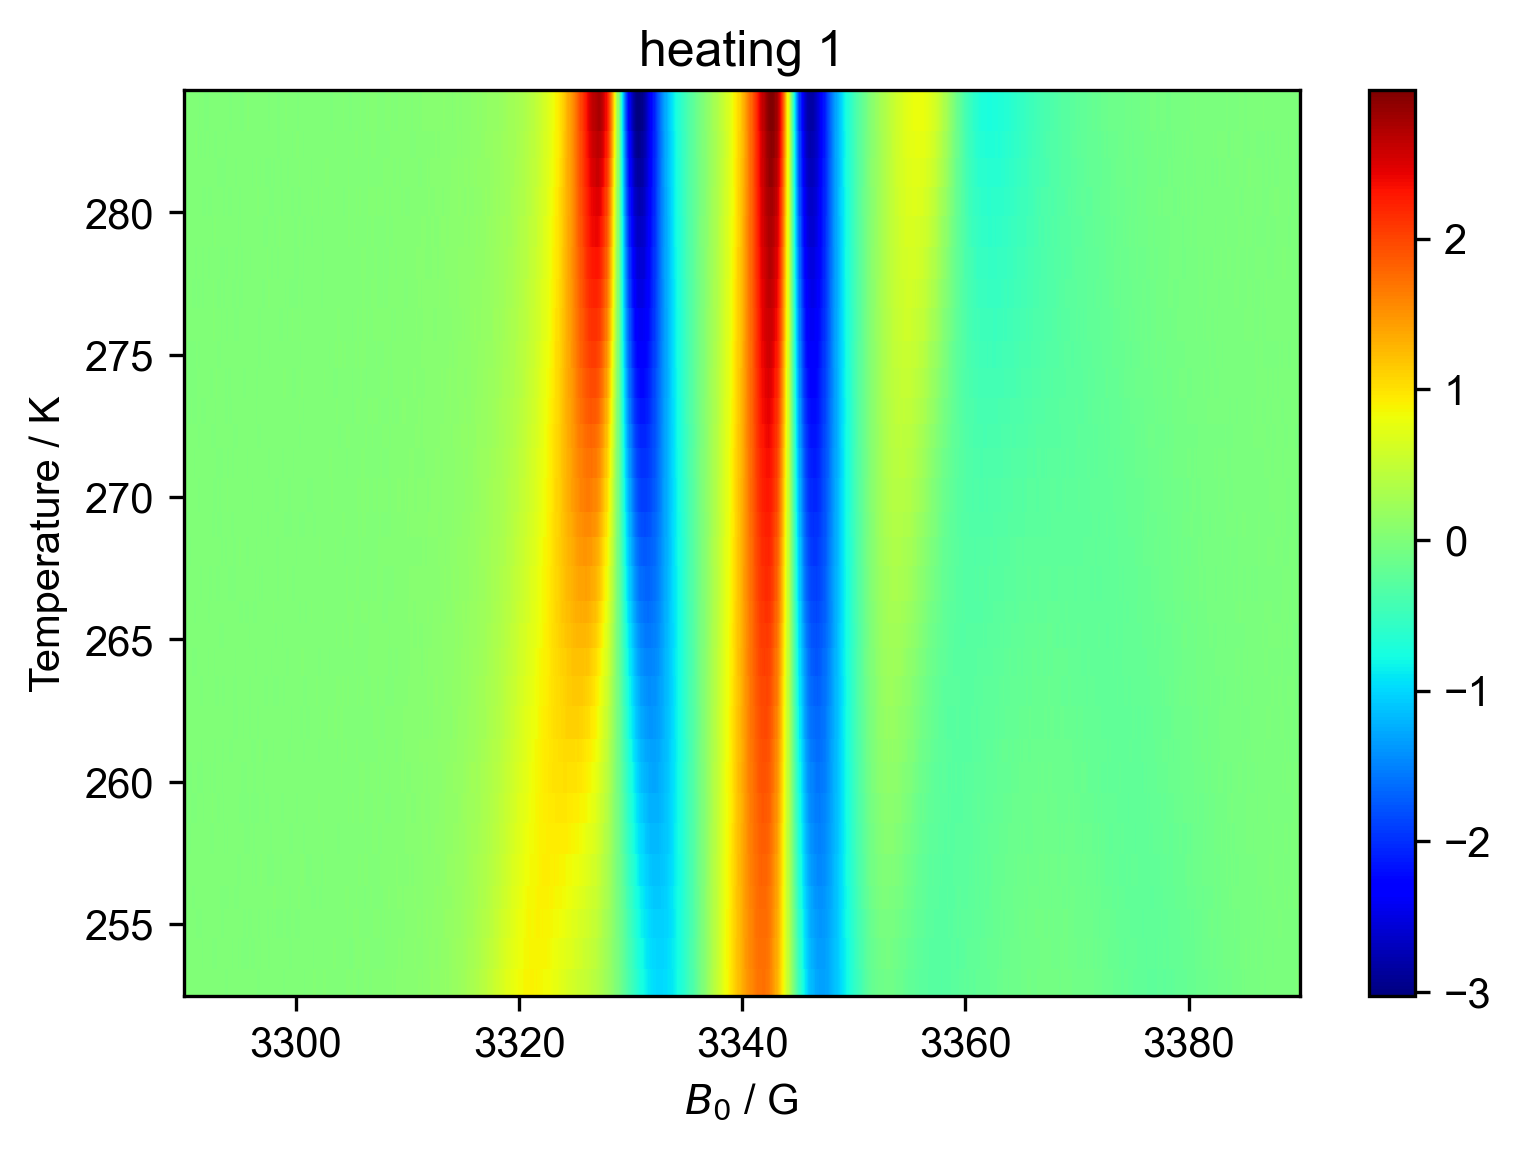

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("heating 1")

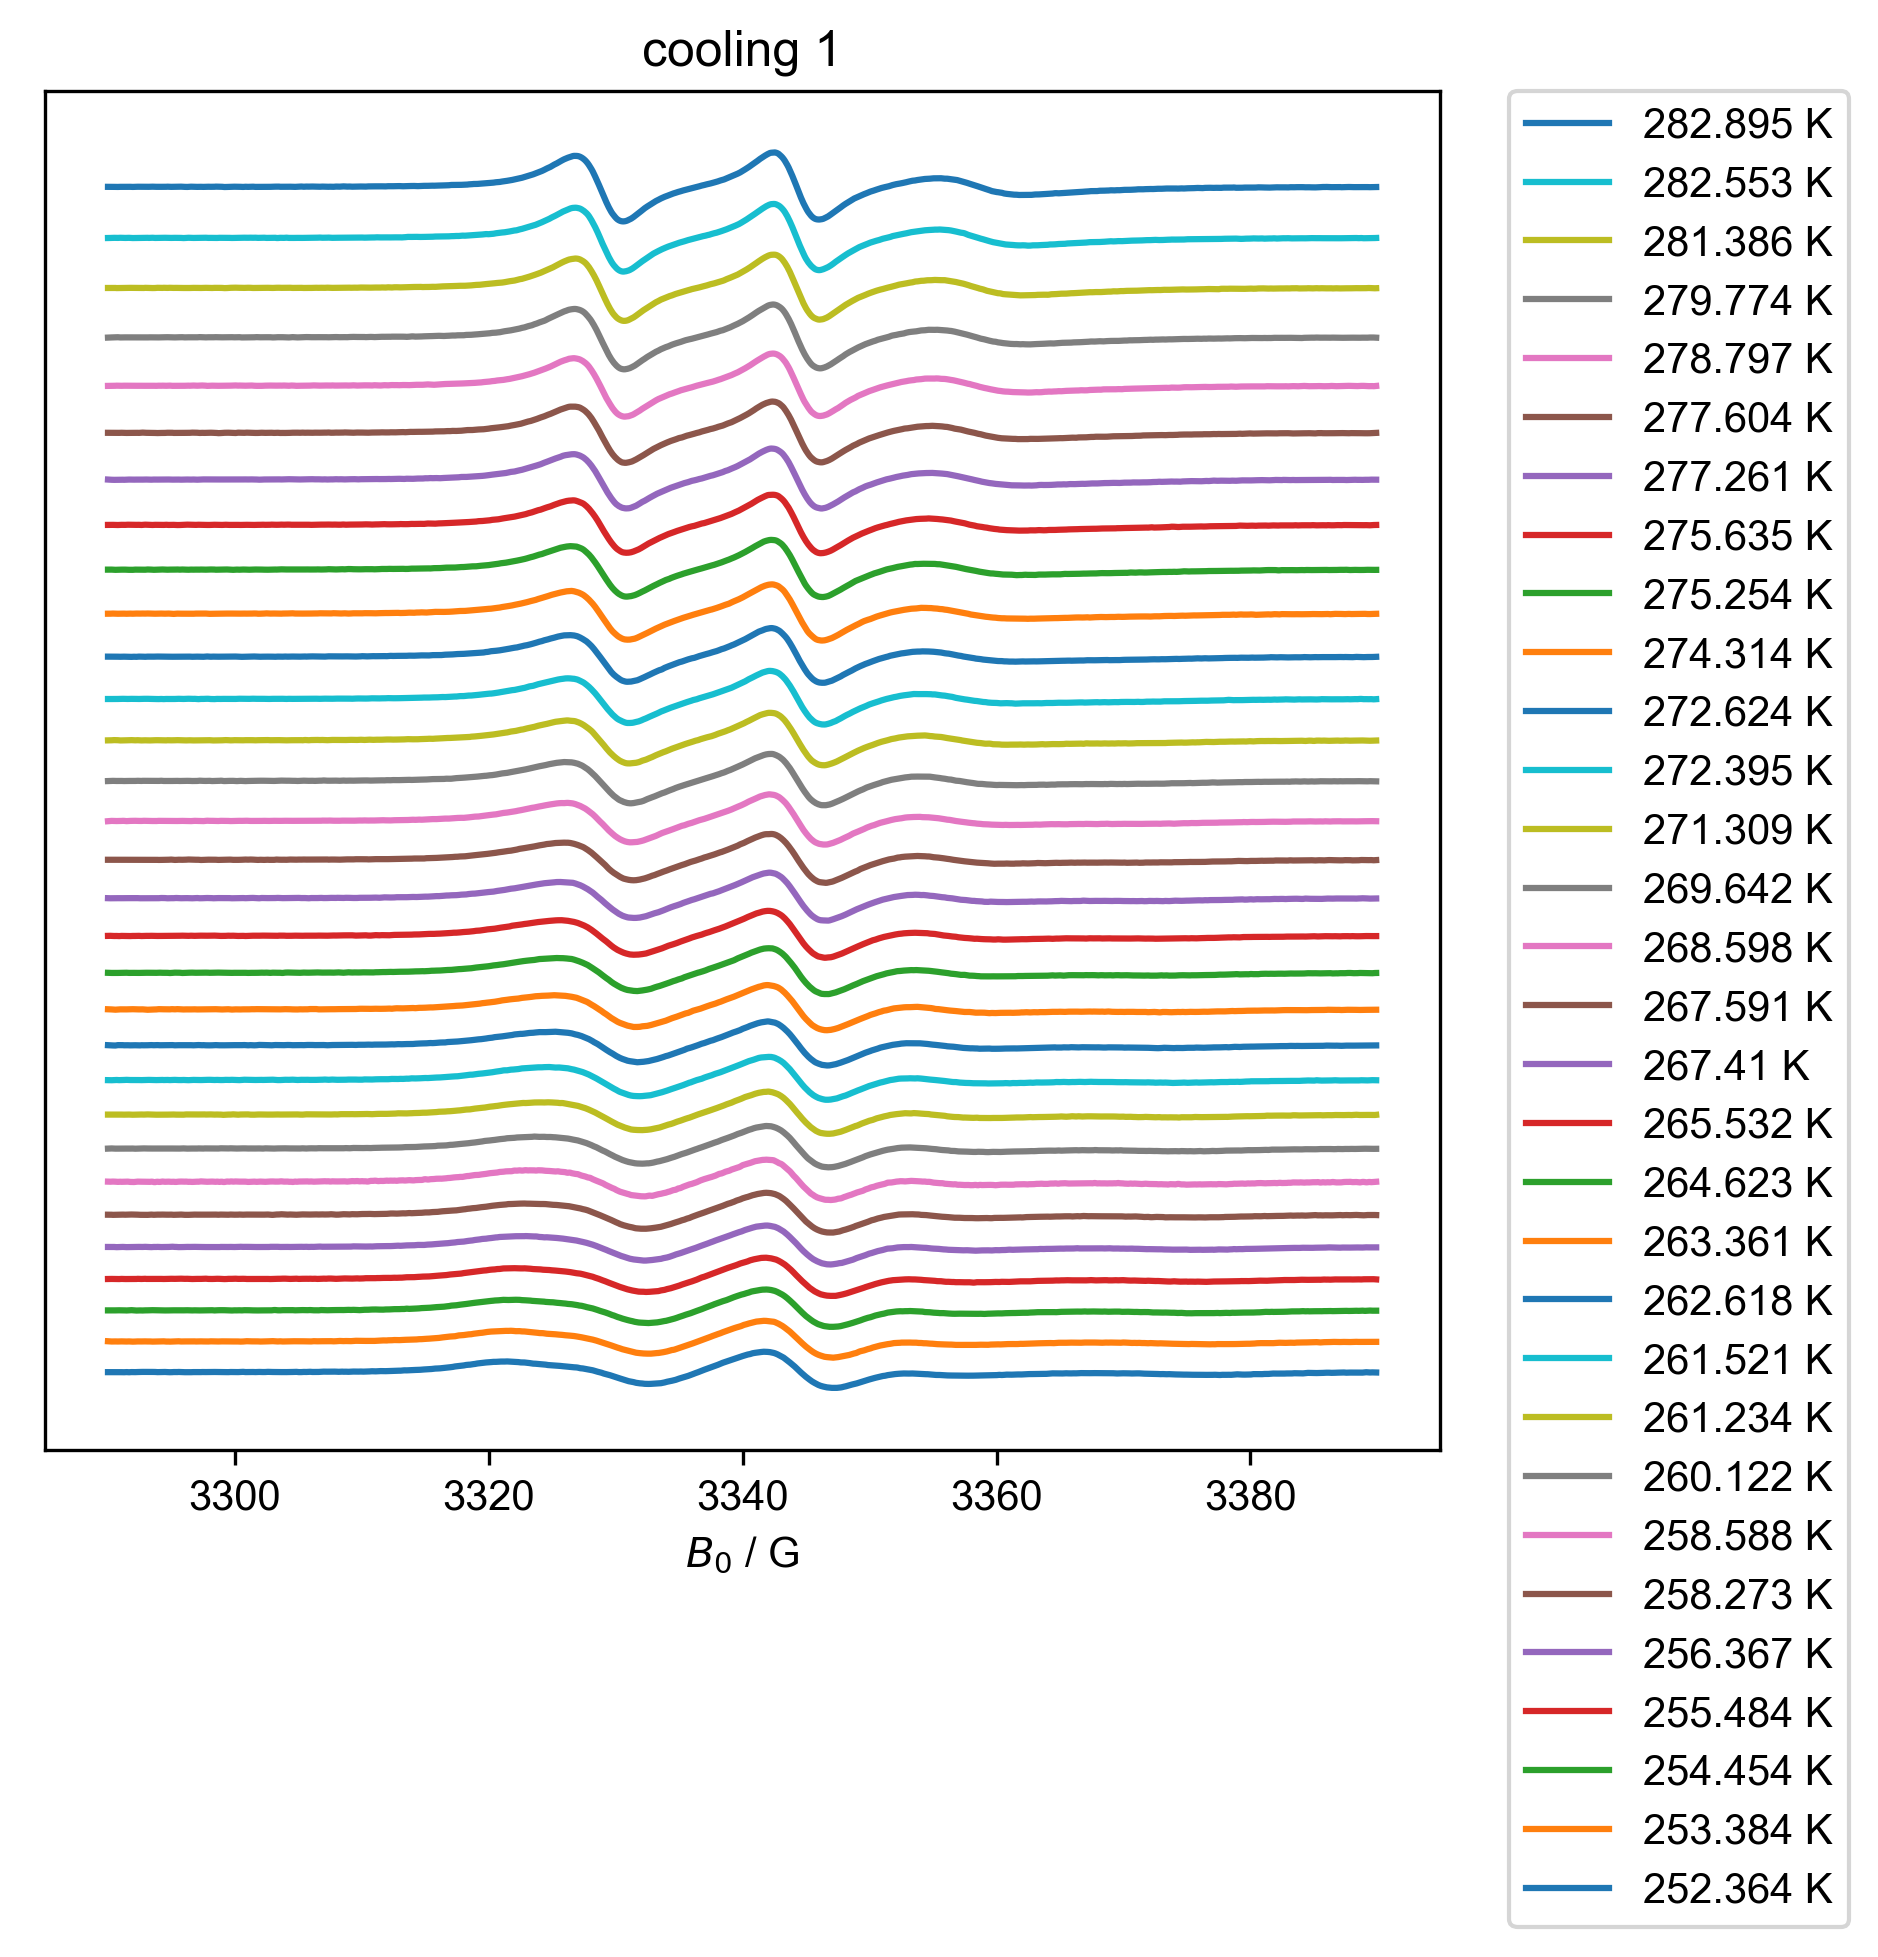

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("cooling 1", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

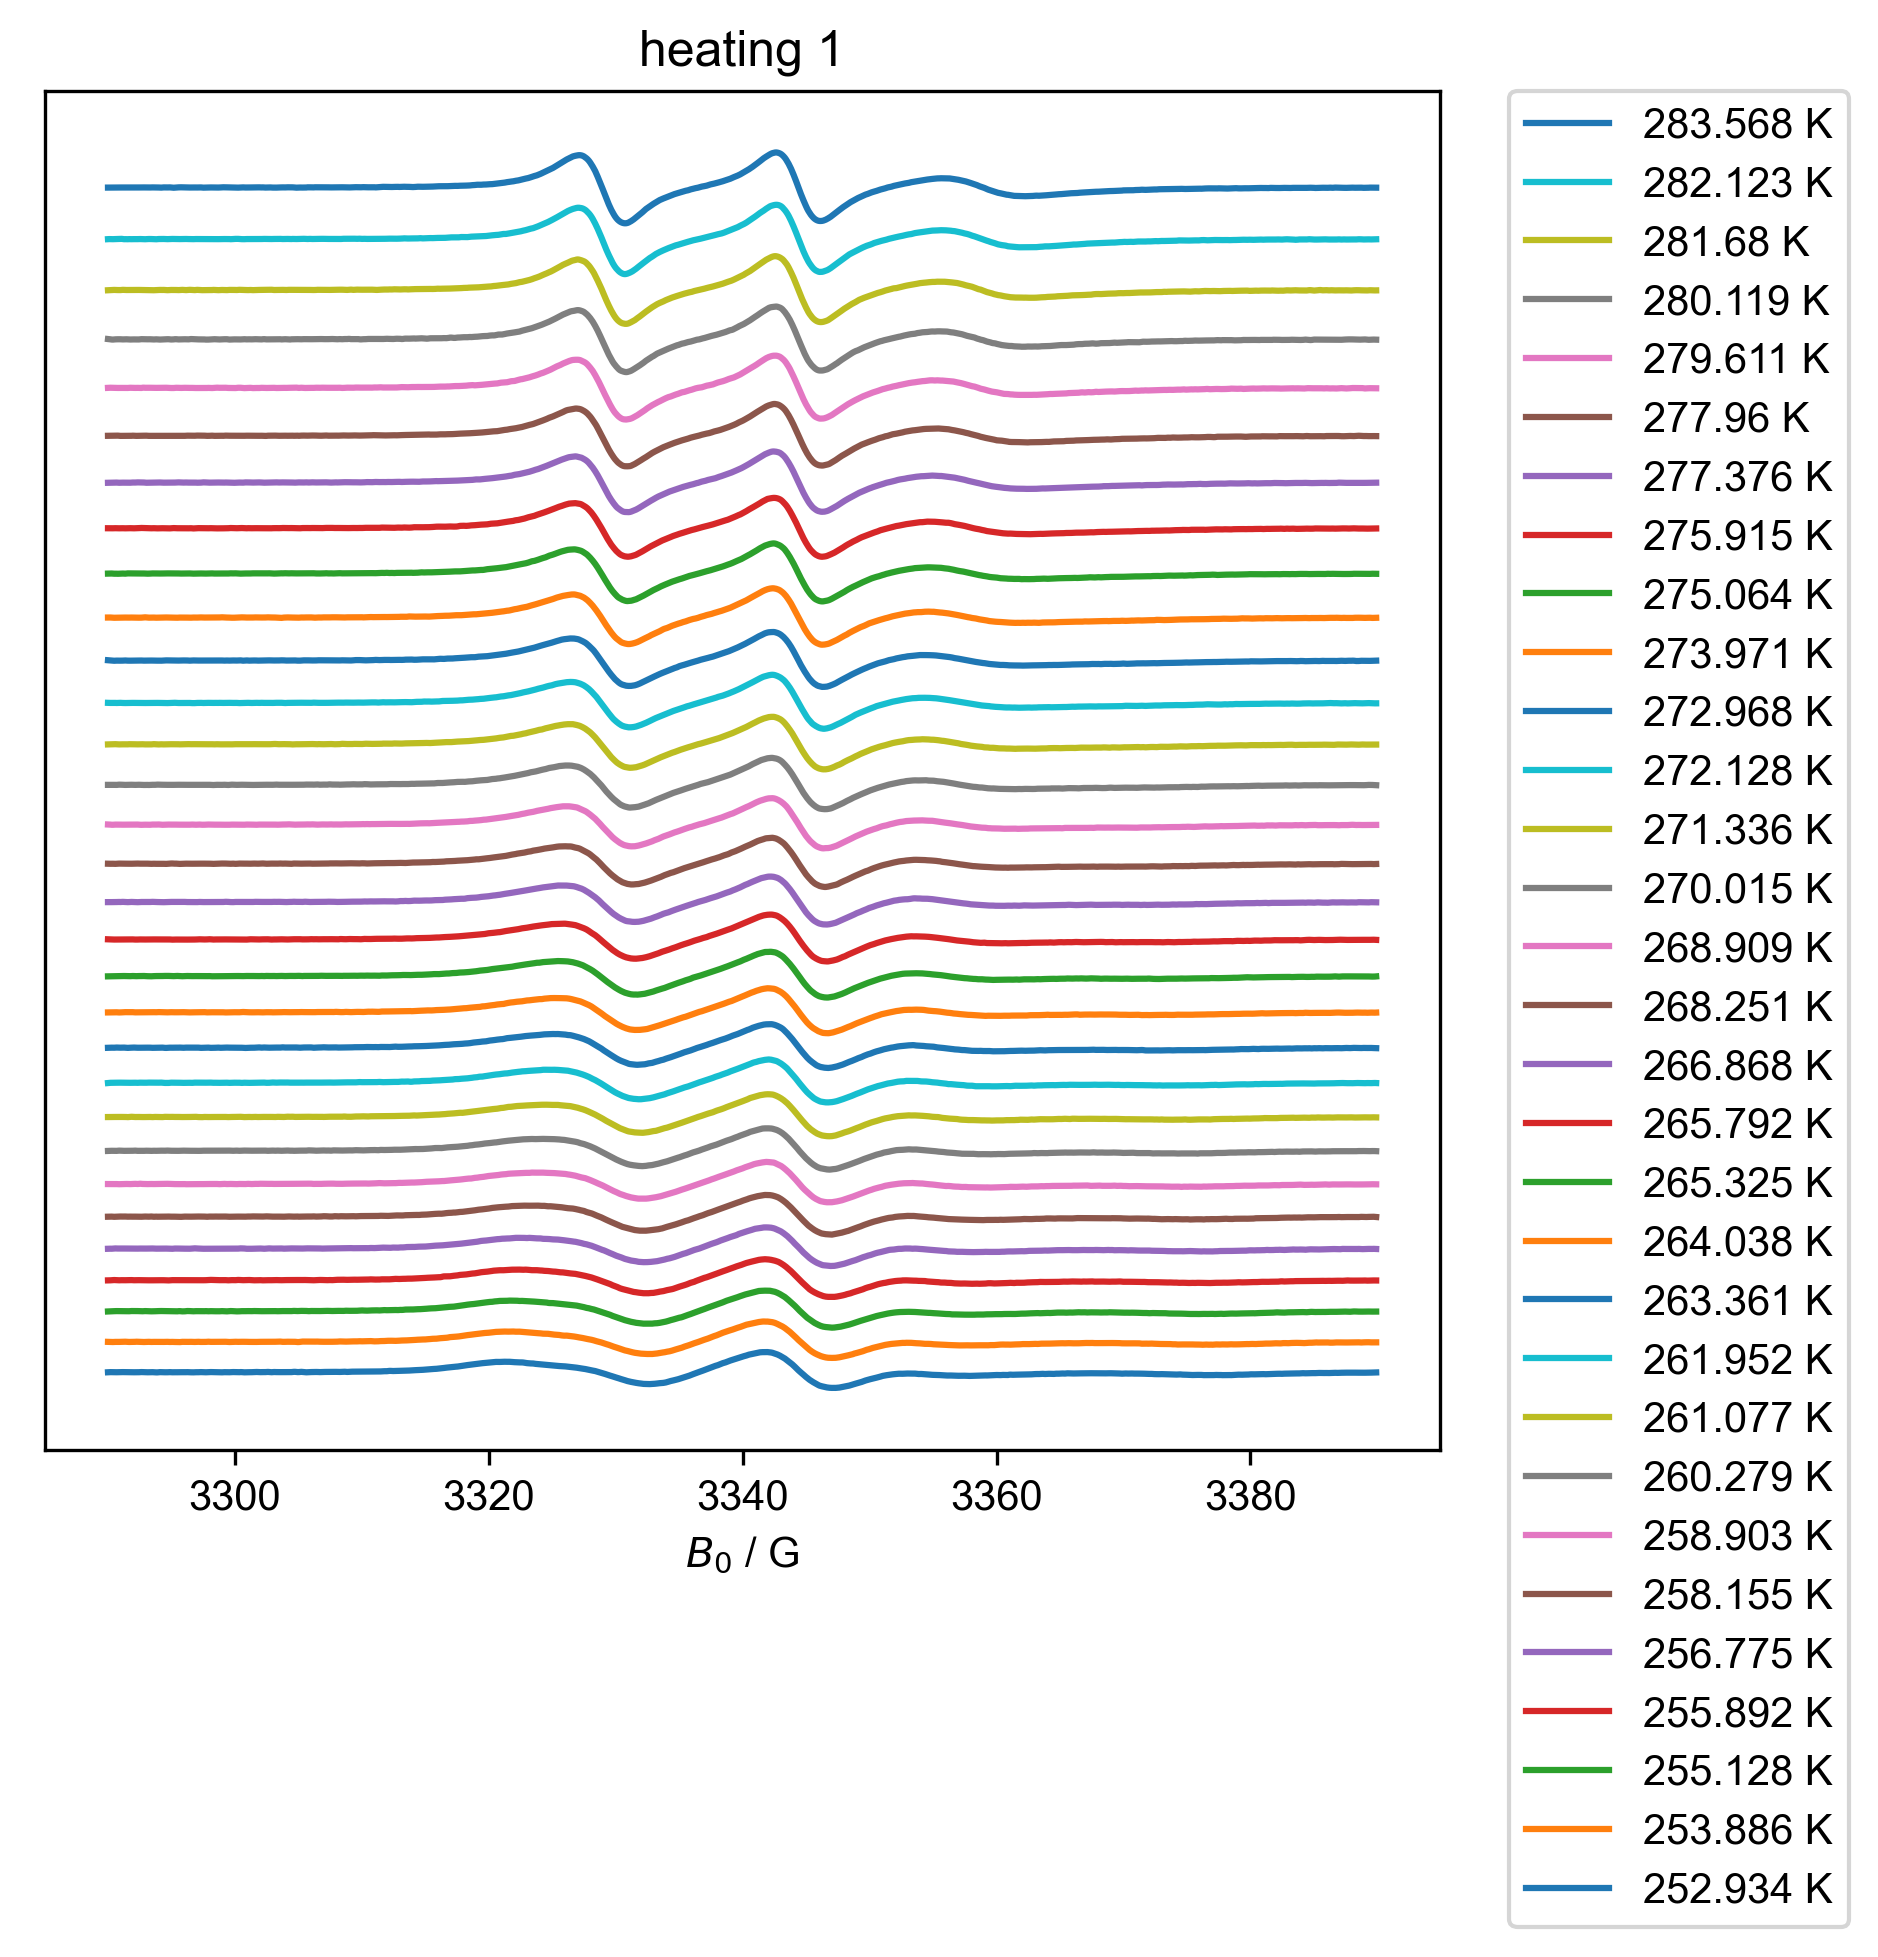

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("heating 1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[252.364 253.384 254.454 255.484 256.367 258.273 258.588 260.122 261.234
 261.521 262.618 263.361 264.623 265.532 267.41  267.591 268.598 269.642
 271.309 272.395 272.624 274.314 275.254 275.635 277.261 277.604 278.797
 279.774 281.386 282.553 282.895]
[252.934 253.886 255.128 255.892 256.775 258.155 258.903 260.279 261.077
 261.952 263.361 264.038 265.325 265.792 266.868 268.251 268.909 270.015
 271.336 272.128 272.968 273.971 275.064 275.915 277.376 277.96  279.611
 280.119 281.68  282.123 283.568]


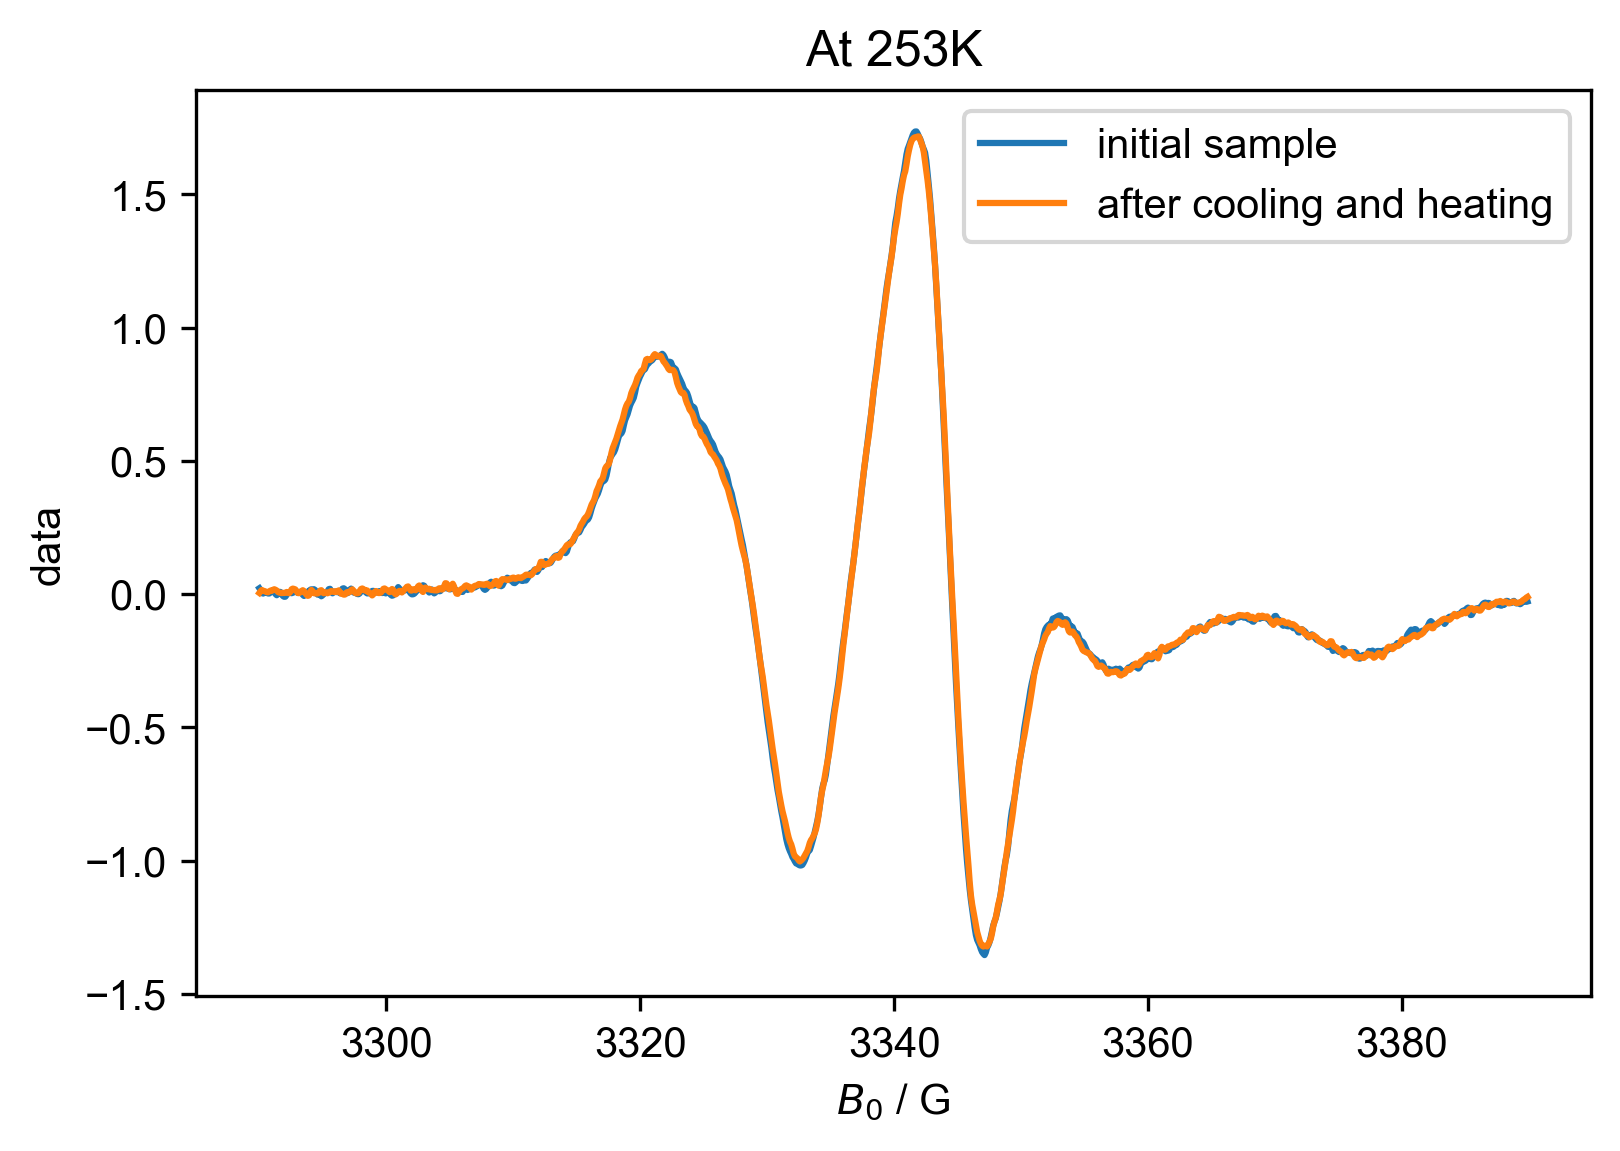

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[252.364 253.384 254.454 255.484 256.367 258.273 258.588 260.122 261.234
 261.521 262.618 263.361 264.623 265.532 267.41  267.591 268.598 269.642
 271.309 272.395 272.624 274.314 275.254 275.635 277.261 277.604 278.797
 279.774 281.386 282.553 282.895]
[252.934 253.886 255.128 255.892 256.775 258.155 258.903 260.279 261.077
 261.952 263.361 264.038 265.325 265.792 266.868 268.251 268.909 270.015
 271.336 272.128 272.968 273.971 275.064 275.915 277.376 277.96  279.611
 280.119 281.68  282.123 283.568]


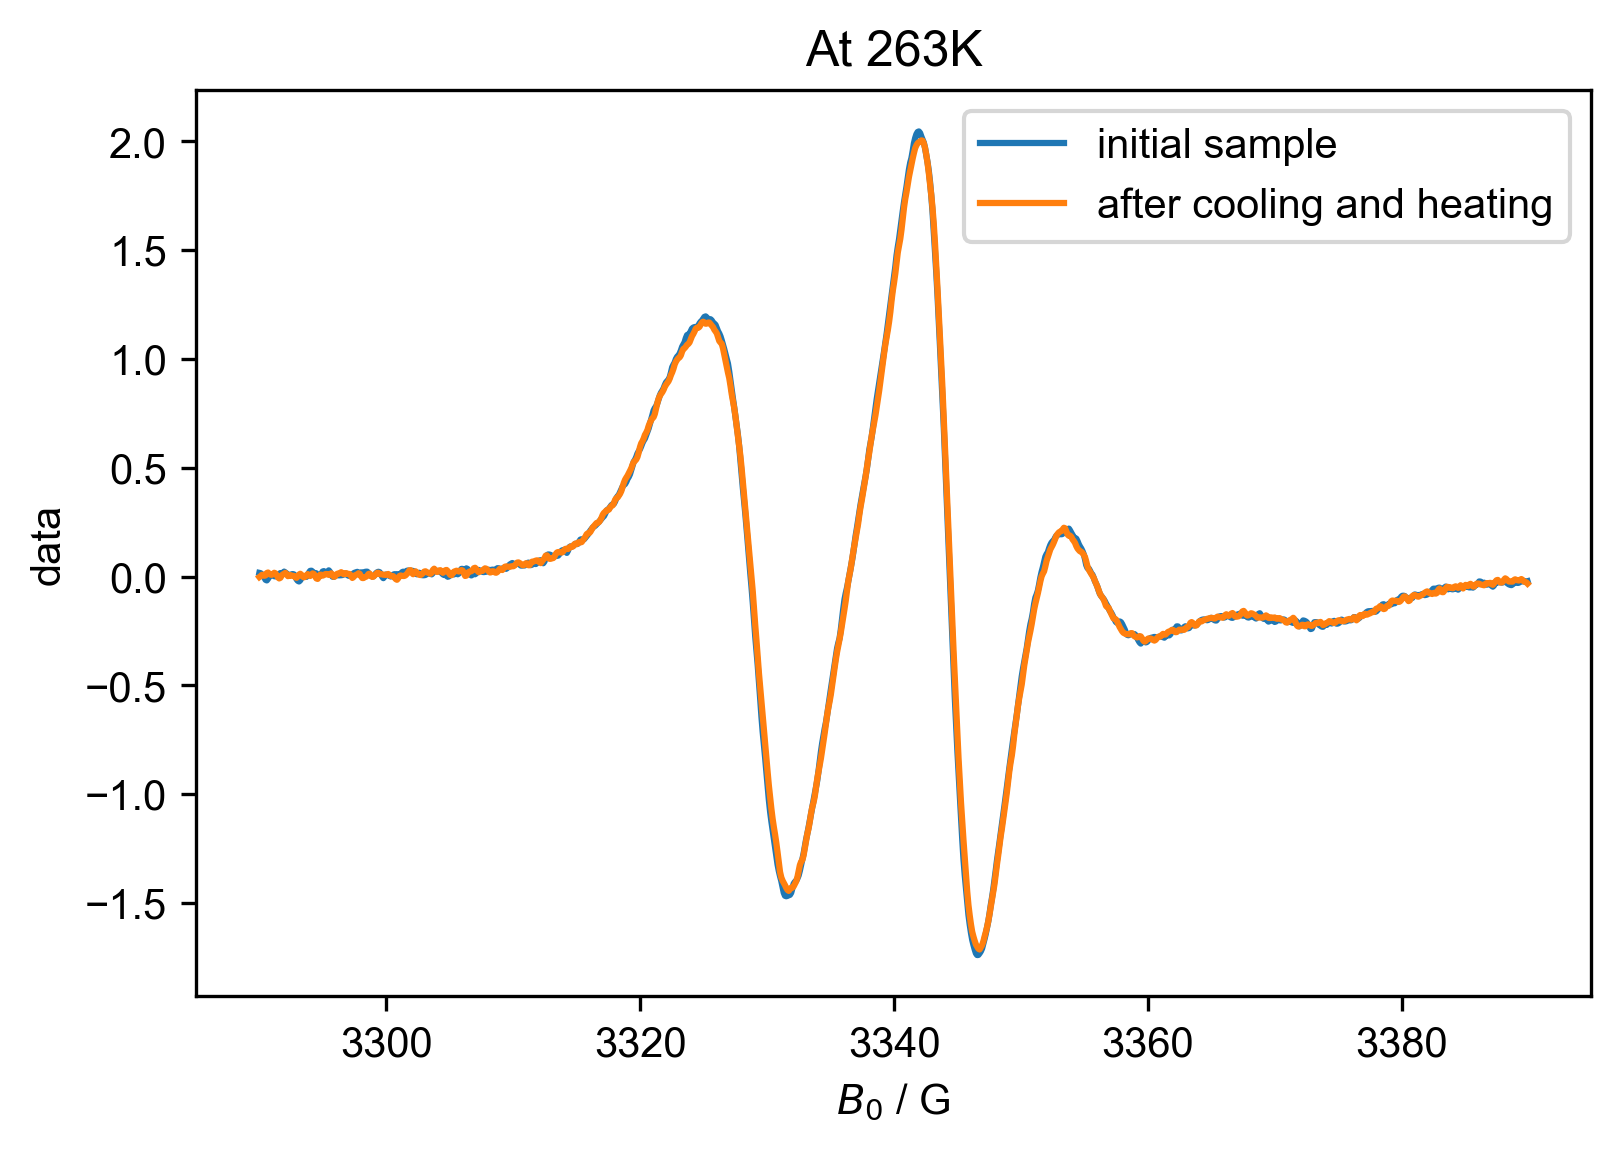

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[252.364 253.384 254.454 255.484 256.367 258.273 258.588 260.122 261.234
 261.521 262.618 263.361 264.623 265.532 267.41  267.591 268.598 269.642
 271.309 272.395 272.624 274.314 275.254 275.635 277.261 277.604 278.797
 279.774 281.386 282.553 282.895]
[252.934 253.886 255.128 255.892 256.775 258.155 258.903 260.279 261.077
 261.952 263.361 264.038 265.325 265.792 266.868 268.251 268.909 270.015
 271.336 272.128 272.968 273.971 275.064 275.915 277.376 277.96  279.611
 280.119 281.68  282.123 283.568]


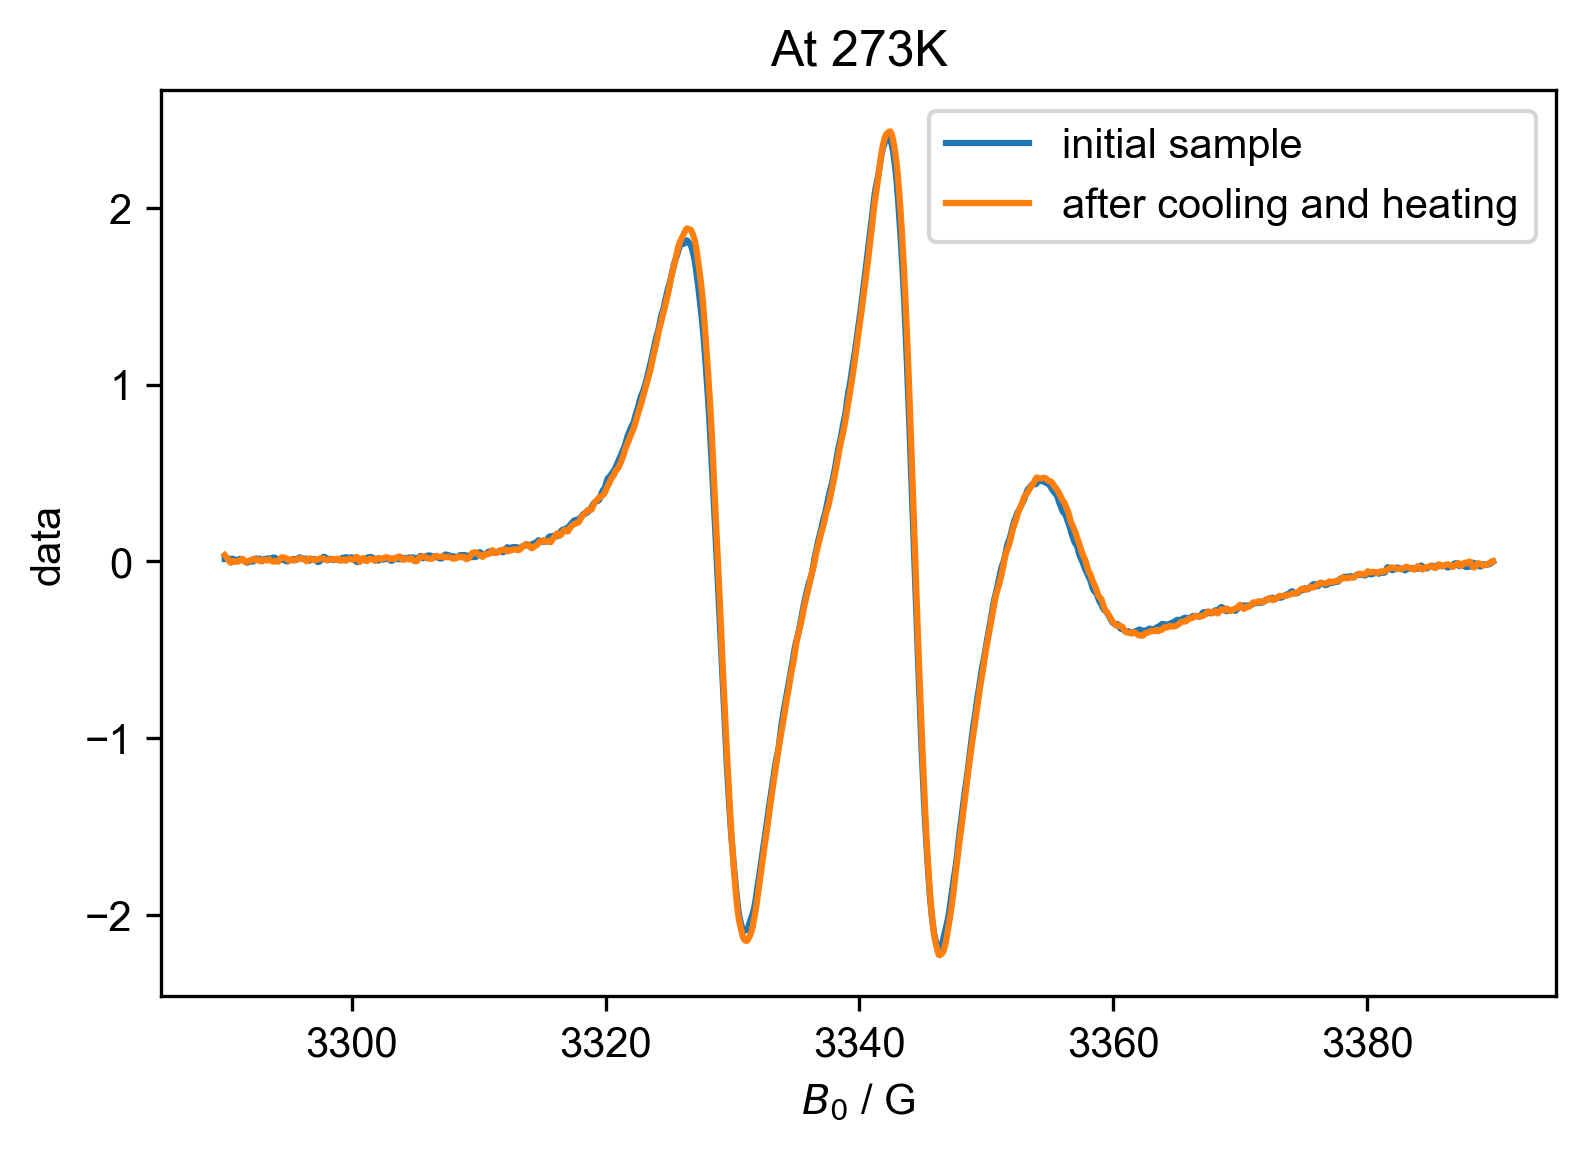

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[252.364 253.384 254.454 255.484 256.367 258.273 258.588 260.122 261.234
 261.521 262.618 263.361 264.623 265.532 267.41  267.591 268.598 269.642
 271.309 272.395 272.624 274.314 275.254 275.635 277.261 277.604 278.797
 279.774 281.386 282.553 282.895]
[252.934 253.886 255.128 255.892 256.775 258.155 258.903 260.279 261.077
 261.952 263.361 264.038 265.325 265.792 266.868 268.251 268.909 270.015
 271.336 272.128 272.968 273.971 275.064 275.915 277.376 277.96  279.611
 280.119 281.68  282.123 283.568]


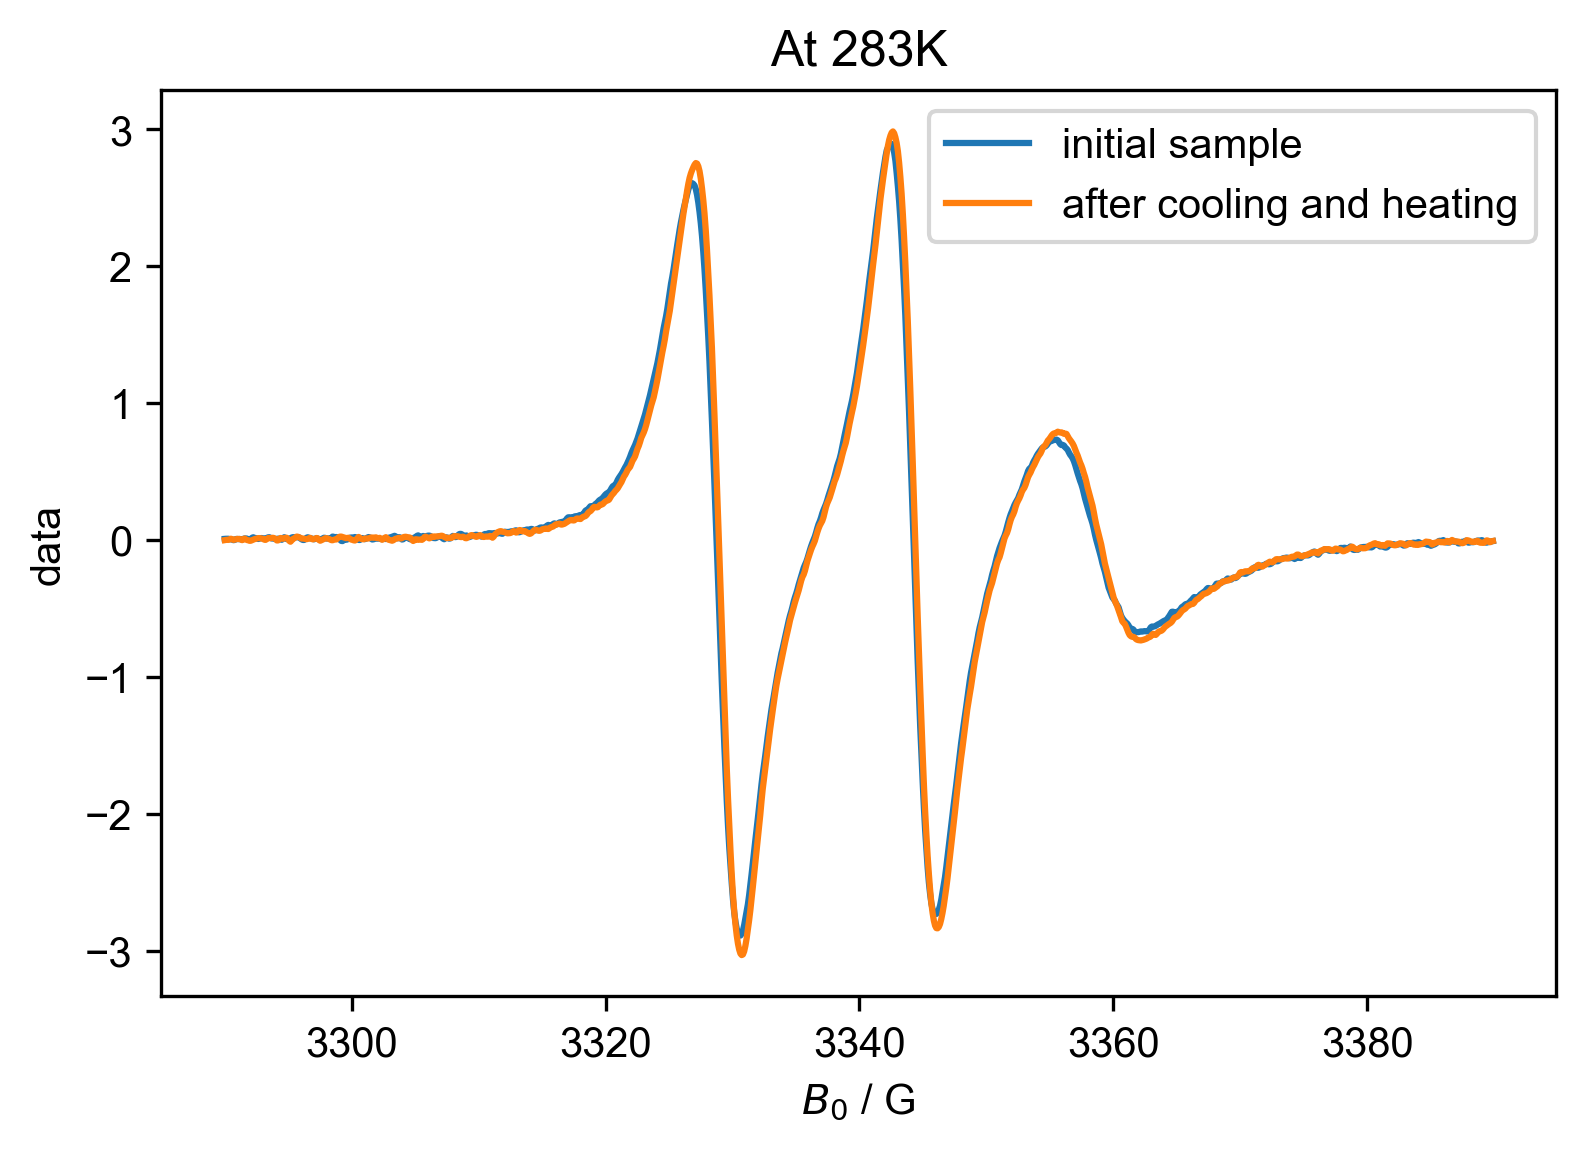

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

In [15]:
# #Normalized
# figure(dpi=300, figsize=(7,4))
# plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
# plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
# title("Normalized TEMPO-SO$_4$ w$_0= 20$ in Dodecane near room temperature (283K)")
# legend()

[252.364 253.384 254.454 255.484 256.367 258.273 258.588 260.122 261.234
 261.521 262.618 263.361 264.623 265.532 267.41  267.591 268.598 269.642
 271.309 272.395 272.624 274.314 275.254 275.635 277.261 277.604 278.797
 279.774 281.386 282.553 282.895]
[252.934 253.886 255.128 255.892 256.775 258.155 258.903 260.279 261.077
 261.952 263.361 264.038 265.325 265.792 266.868 268.251 268.909 270.015
 271.336 272.128 272.968 273.971 275.064 275.915 277.376 277.96  279.611
 280.119 281.68  282.123 283.568]


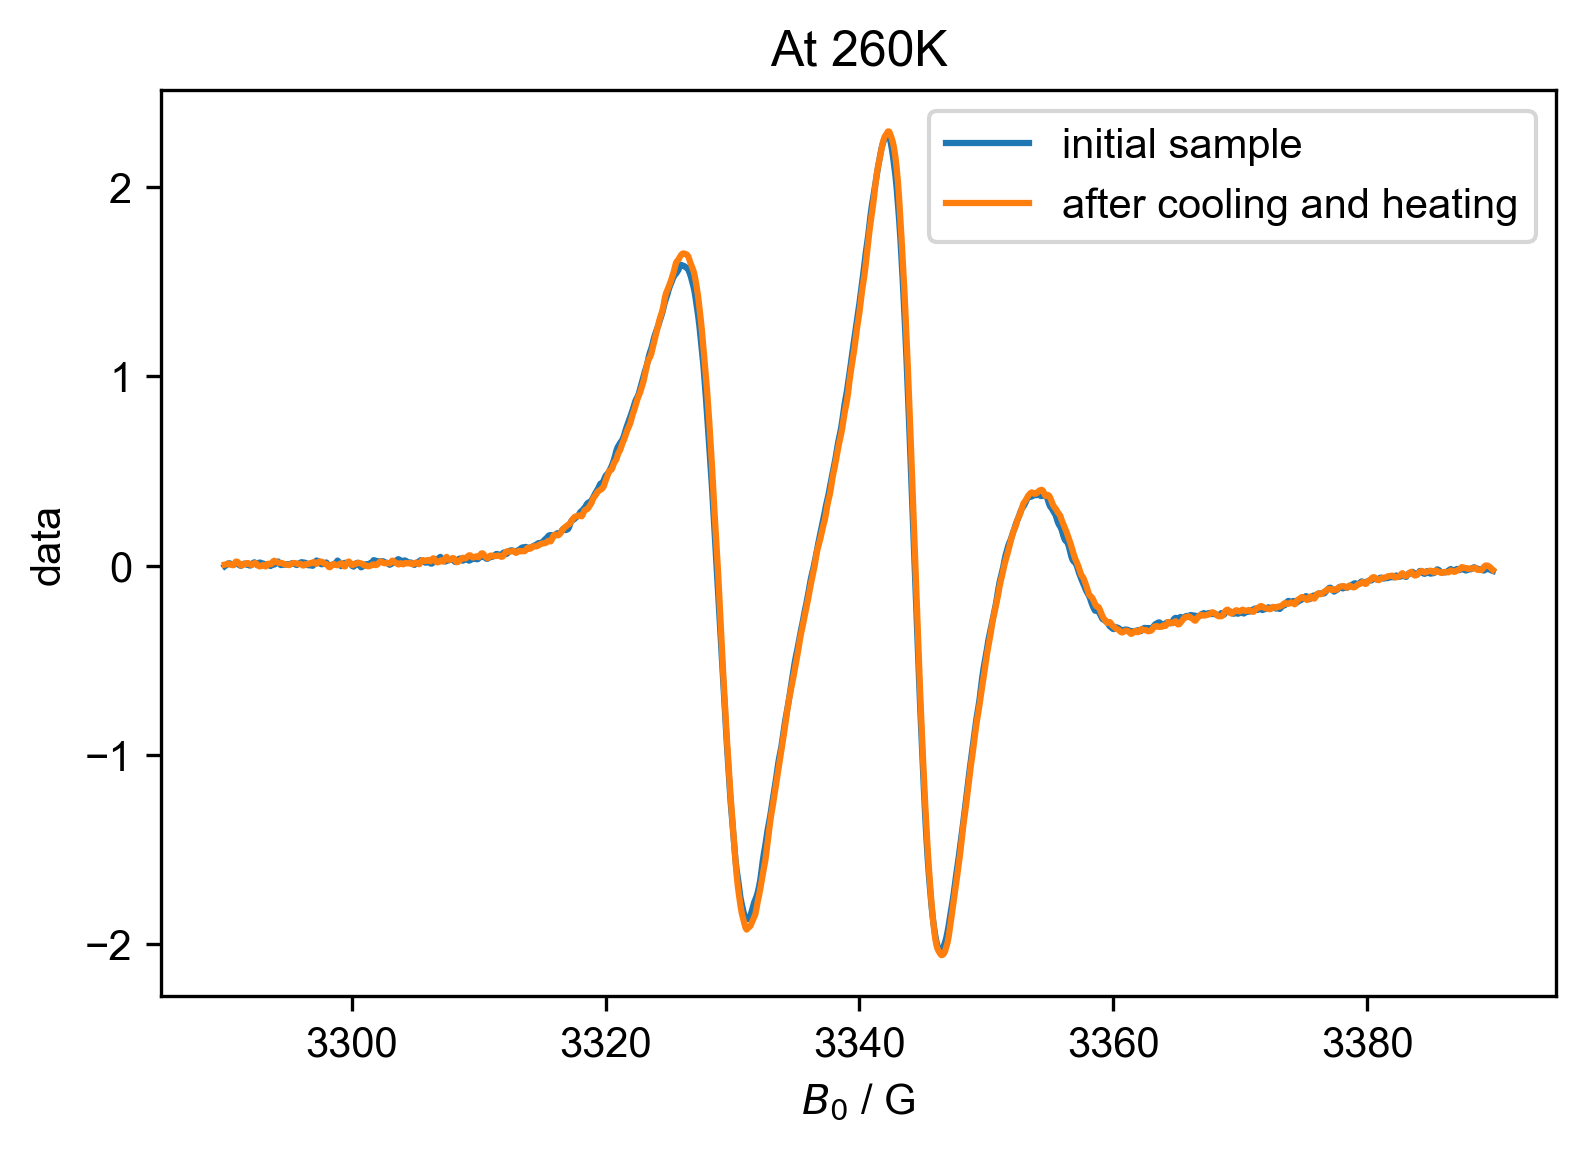

In [39]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":270], label="initial sample")
plot(d2["Temperature":270], label="after cooling and heating")
title("At 260K")
legend()

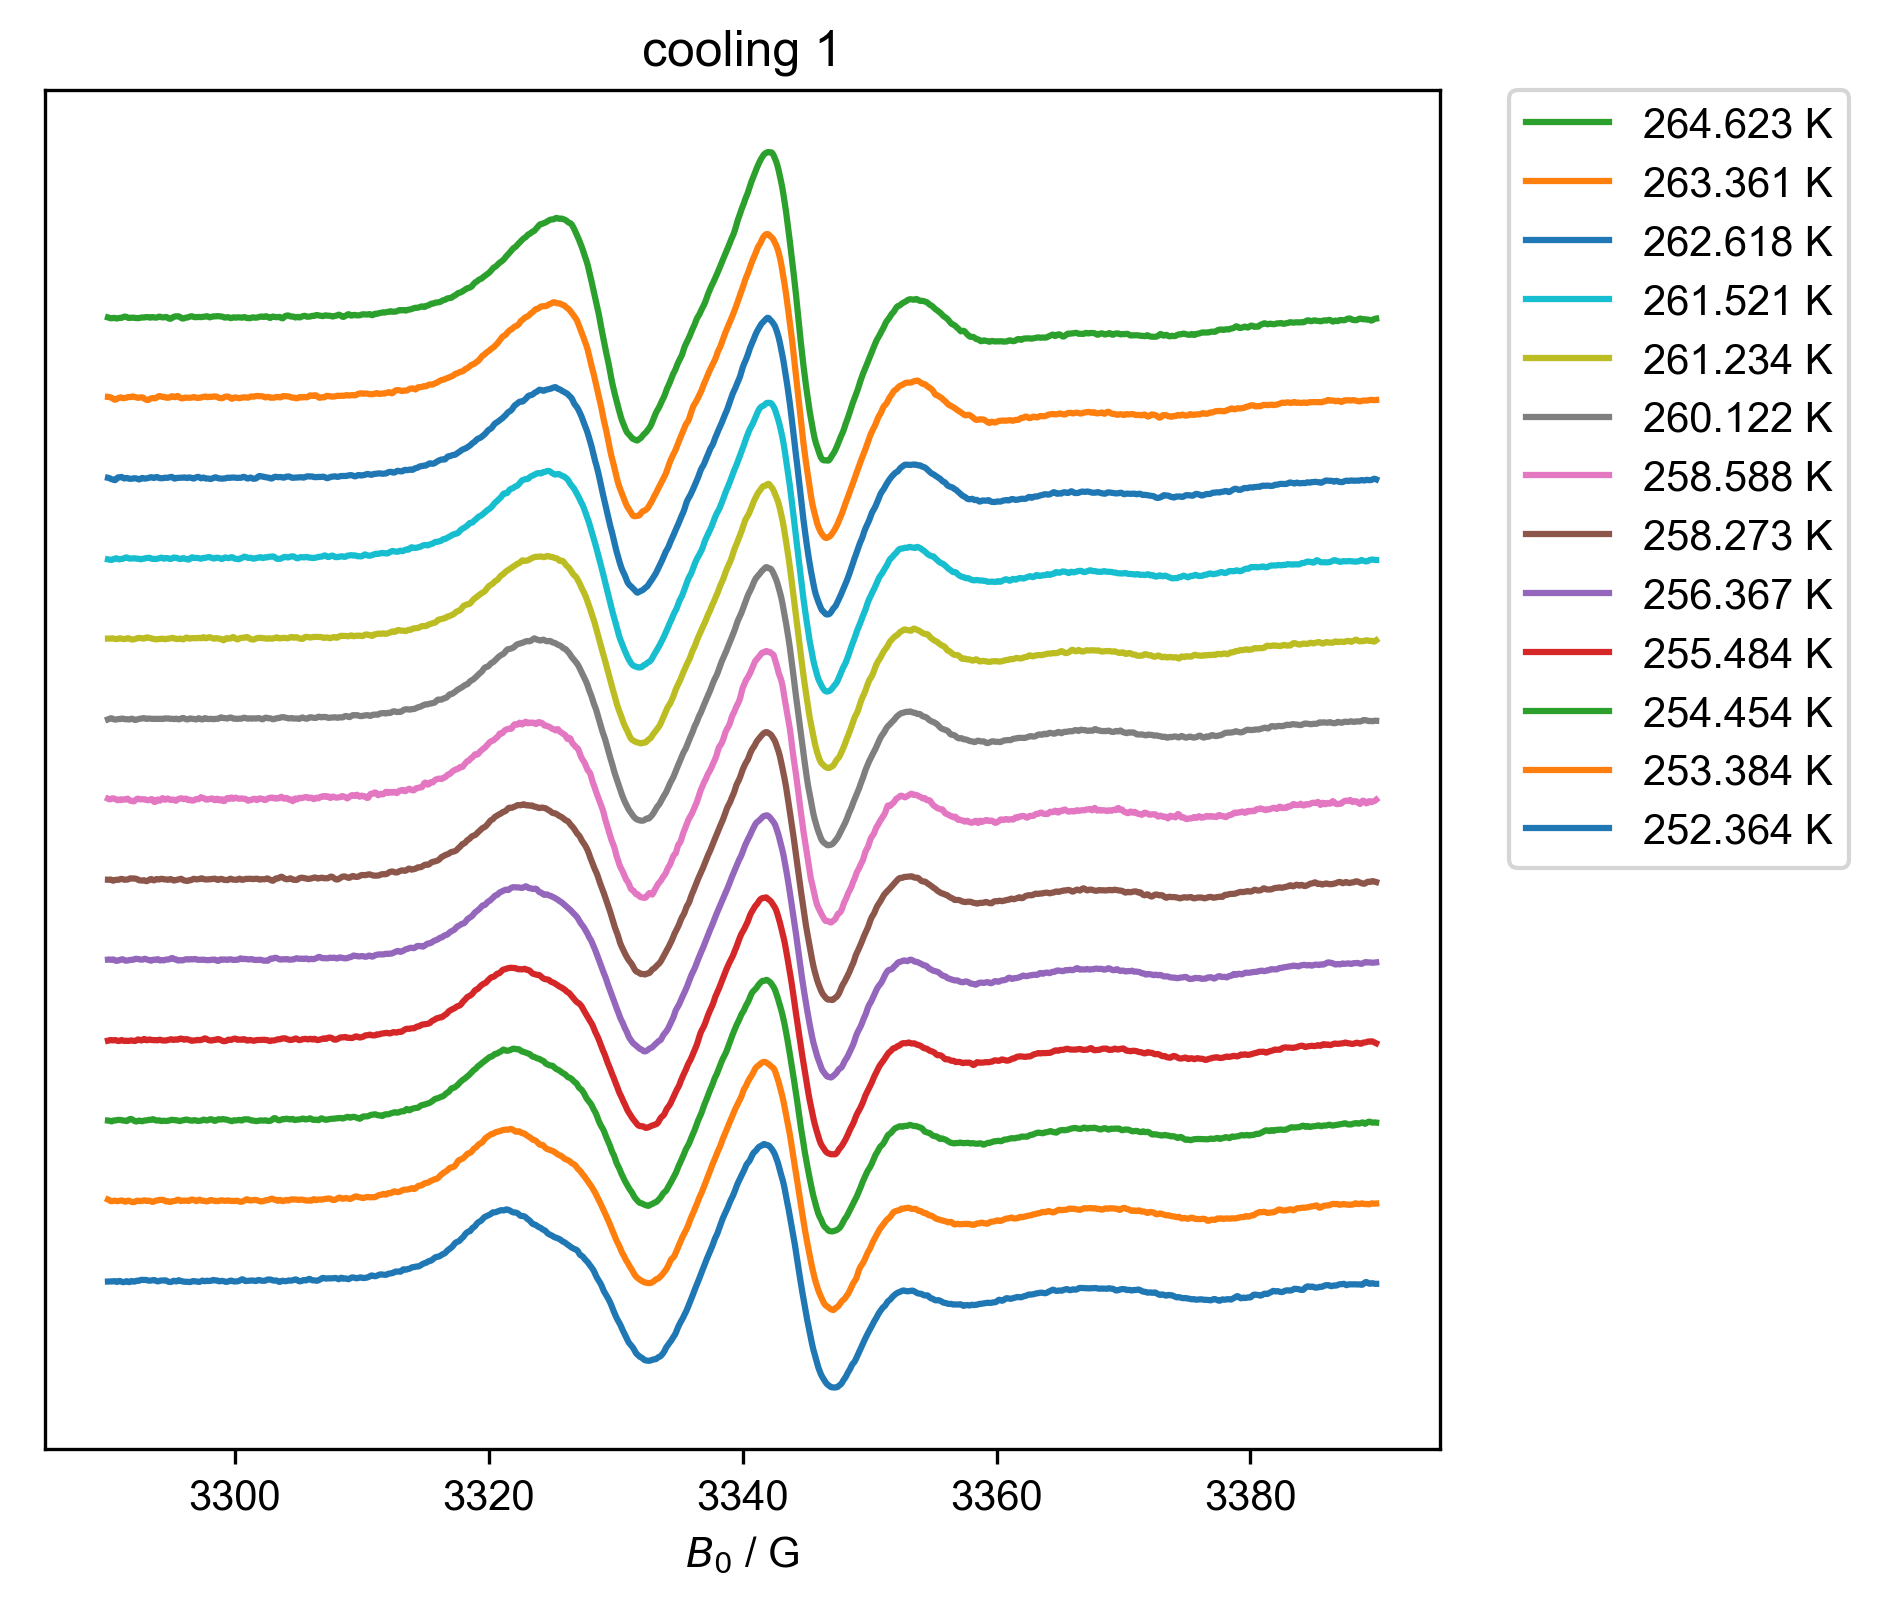

In [46]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("cooling 1", (250, 265))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
#         offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        offset +=1
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

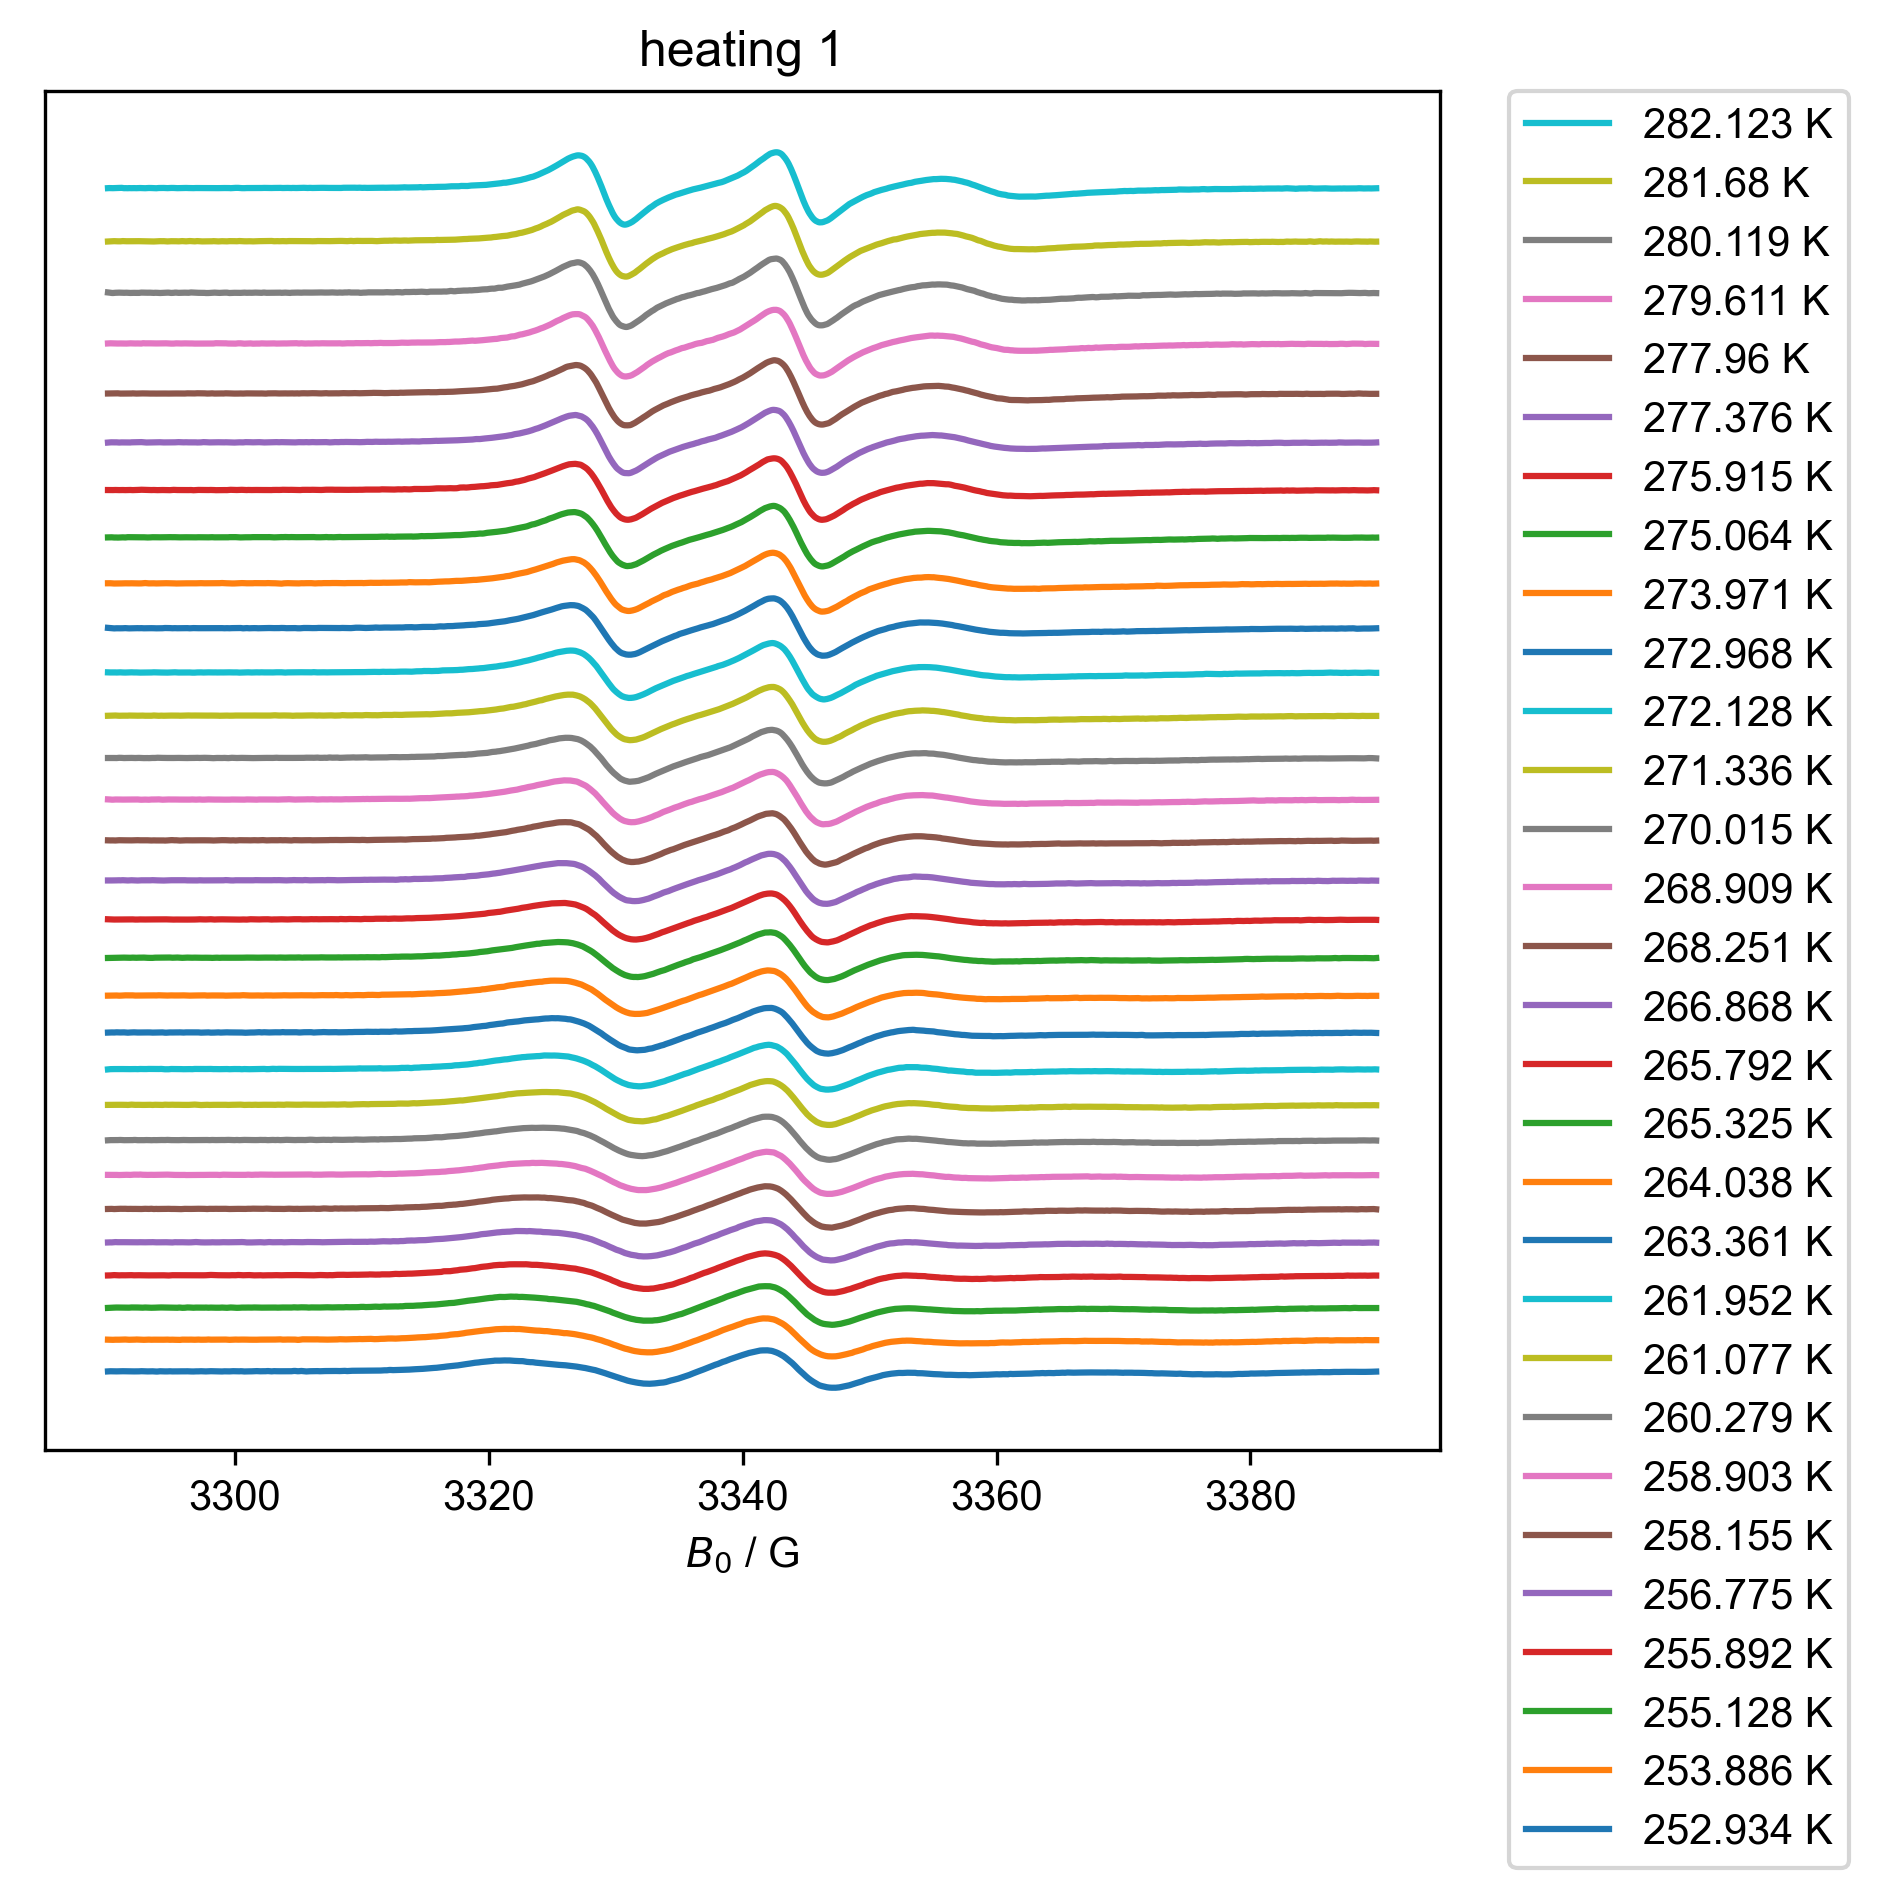

In [44]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("heating 1", (250, 283)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
#         offset += 1
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()